# Анализ лояльности пользователей Яндекс Афиши


Цель проекта — изучить повторные покупки пользователей и выяснить, какие признаки
первого заказа связаны с возвращением на платформу.

## Этапы выполнения проекта

### 1. Загрузка данных и их предобработка

---

**Задача 1.1:** Напишите SQL-запрос, выгружающий в датафрейм pandas необходимые данные. Параметры подключения берутся из локального файла `.env`. Для настройки окружения и запуска используйте `README.md`.

Для выгрузки используйте запрос из предыдущего урока и библиотеку SQLAlchemy.

Выгрузка из базы данных SQL должна позволить собрать следующие данные:

- `user_id` — уникальный идентификатор пользователя, совершившего заказ;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ (`mobile` — мобильные устройства, `desktop` — стационарные);
- `order_id` — уникальный идентификатор заказа;
- `order_dt` — дата создания заказа (используйте данные `created_dt_msk`);
- `order_ts` — дата и время создания заказа (используйте данные `created_ts_msk`);
- `currency_code` — валюта оплаты;
- `revenue` — выручка от заказа;
- `tickets_count` — количество купленных билетов;
- `days_since_prev` — количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой — значение пропущено;
- `event_id` — уникальный идентификатор мероприятия;
- `service_name` — название билетного оператора;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `region_name` — название региона, в котором прошло мероприятие;
- `city_name` — название города, в котором прошло мероприятие.

---

In [ ]:
# Установите зависимости из requirements.txt перед первым запуском.
# В README описана установка в отдельное виртуальное окружение.

In [ ]:
# При необходимости установить зависимости из самого ноутбука:
# %pip install -r requirements.txt
# После установки перезапустите ядро и выполняйте ячейки сверху вниз.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import phik
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from IPython.display import display
from dotenv import load_dotenv

pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid')

In [ ]:
# Файл .env должен лежать рядом с ноутбуком.
# Параметры подключения не записываются в публикуемый код.
load_dotenv('.env')

db_config = {
    'user': os.environ['AFISHA_USER'],
    'pwd': os.environ['AFISHA_PASSWORD'],
    'host': os.environ['AFISHA_HOST'],
    'port': int(os.environ['AFISHA_PORT']),
    'db': os.environ['AFISHA_DATABASE'],
}

connection_string = URL.create(
    drivername='postgresql+psycopg2',
    username=db_config['user'],
    password=db_config['pwd'],
    host=db_config['host'],
    port=db_config['port'],
    database=db_config['db'],
)

engine = create_engine(
    connection_string,
    connect_args={
        'sslmode': os.environ['AFISHA_SSLMODE'],
        'connect_timeout': 20,
    },
)

Соединяем покупки с мероприятиями, городами и регионами. Перед соединением проверяем ключи справочников, после — число строк и заказов. Схема `afisha` используется для внешней базы PostgreSQL из задания. Фильтрация устройств и фильмов выполняется до расчёта интервала. `LAG()` берёт дату предыдущей покупки пользователя в порядке времени и номера заказа; у первого заказа интервал пустой, покупки в один день дают 0. Ограничения `LIMIT 10` нет. Транзакция только для чтения.

In [5]:
query = """
SELECT
    p.user_id,
    p.device_type_canonical,
    p.order_id,
    p.created_dt_msk AS order_dt,
    p.created_ts_msk AS order_ts,
    p.currency_code,
    p.revenue,
    p.tickets_count,
    p.created_dt_msk::date
        - LAG(p.created_dt_msk::date) OVER (
            PARTITION BY p.user_id
            ORDER BY p.created_ts_msk, p.order_id
        ) AS days_since_prev,
    p.event_id,
    e.event_name_code AS event_name,
    p.service_name,
    e.event_type_main,
    r.region_name,
    c.city_name
FROM afisha.purchases AS p
LEFT JOIN afisha.events AS e ON p.event_id = e.event_id
LEFT JOIN afisha.city AS c ON e.city_id = c.city_id
LEFT JOIN afisha.regions AS r ON c.region_id = r.region_id
WHERE p.device_type_canonical IN ('mobile', 'desktop')
    AND e.event_type_main <> 'фильм'
ORDER BY p.user_id
"""

key_query = """
SELECT 'events.event_id' AS key_name, COUNT(*) AS rows,
       COUNT(*) - COUNT(DISTINCT event_id) AS repeated_or_null
FROM afisha.events
UNION ALL
SELECT 'city.city_id', COUNT(*), COUNT(*) - COUNT(DISTINCT city_id)
FROM afisha.city
UNION ALL
SELECT 'regions.region_id', COUNT(*), COUNT(*) - COUNT(DISTINCT region_id)
FROM afisha.regions
"""

with engine.connect() as connection:
    connection.exec_driver_sql('SET TRANSACTION READ ONLY')
    key_check = pd.read_sql_query(text(key_query), con=connection)
    display(key_check)
    if key_check['repeated_or_null'].sum() > 0:
        raise ValueError('Ключи справочников не уникальны или содержат NULL: проверьте JOIN')
    orders = pd.read_sql_query(text(query), con=connection)

engine.dispose()
orders.head()

,key_name,rows,repeated_or_null
0,events.event_id,22484,0
1,city.city_id,353,0
2,regions.region_id,81,0


,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,service_name,event_type_main,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,Край билетов,театр,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,Мой билет,выставки,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.00,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,За билетом!,другое,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,Лови билет!,другое,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.00,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,Билеты без проблем,стендап,Озернинский край,Родниковецк


---

**Задача 1.2:** Изучите общую информацию о выгруженных данных. Оцените корректность выгрузки и объём полученных данных.

Предположите, какие шаги необходимо сделать на стадии предобработки данных — например, скорректировать типы данных.

Зафиксируйте основную информацию о данных в кратком промежуточном выводе.

---

Знакомство с выгрузкой

Посмотрим размер таблицы, типы данных, пропуски и повторяющиеся номера заказов.
Пропуск в `days_since_prev` у первой покупки — нормальная ситуация, а не ошибка.

In [6]:
print('Строк и столбцов:', orders.shape)
print('Пользователей:', orders['user_id'].nunique())
print('Пустых номеров заказов:', orders['order_id'].isna().sum())
print('Повторяющихся номеров заказов:', orders['order_id'].dropna().duplicated().sum())
print('Полных дубликатов:', orders.duplicated().sum())
orders.info()
display(orders.isna().sum().to_frame('Пропуски'))
print('Одна строка на заказ:', len(orders) == orders['order_id'].nunique())

Строк и столбцов: (290611, 15)
Пользователей: 21933
Пустых номеров заказов: 0
Повторяющихся номеров заказов: 0
Полных дубликатов: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 no

,Пропуски
user_id,0
device_type_canonical,0
order_id,0
order_dt,0
order_ts,0
currency_code,0
revenue,0
tickets_count,0
days_since_prev,21933
event_id,0


Одна строка на заказ: True


In [7]:
orders['order_dt'] = pd.to_datetime(orders['order_dt'])
orders['order_ts'] = pd.to_datetime(orders['order_ts'])
orders['days_since_prev'] = orders['days_since_prev'].astype('Int64')
orders['revenue'] = pd.to_numeric(orders['revenue'])
orders['tickets_count'] = pd.to_numeric(orders['tickets_count'], downcast='integer')

print('Начало периода:', orders['order_dt'].min().date())
print('Конец периода:', orders['order_dt'].max().date())
print('Первых заказов с пустым интервалом:', orders['days_since_prev'].isna().sum())
display(orders['currency_code'].value_counts())
display(orders['device_type_canonical'].value_counts())
display(orders['event_type_main'].value_counts())
print('Покупок в один день с предыдущей:', orders['days_since_prev'].eq(0).sum())
print('Отрицательных интервалов:', orders['days_since_prev'].lt(0).sum())

Начало периода: 2024-06-01
Конец периода: 2024-10-31
Первых заказов с пустым интервалом: 21933


rub    285542
kzt      5069
Name: currency_code, dtype: int64

mobile     232490
desktop     58121
Name: device_type_canonical, dtype: int64

концерты    115276
театр        67321
другое       65867
спорт        21911
стендап      13393
выставки      4854
ёлки          1989
Name: event_type_main, dtype: int64

Покупок в один день с предыдущей: 184052
Отрицательных интервалов: 0


**Промежуточный вывод.** Мы получили таблицу заказов с признаками мероприятий
и места проведения. Даты приведены к `datetime`, интервал — к целому типу,
допускающему пропуски. Объём, период и качество выгрузки показаны выше.
Далее нужно привести выручку к одной валюте и изучить её распределение.

---

###  2. Предобработка данных

Выполните все стандартные действия по предобработке данных:

---

**Задача 2.1:** Данные о выручке сервиса представлены в российских рублях и казахстанских тенге. Приведите выручку к единой валюте — российскому рублю.

Для этого используйте датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год — `final_tickets_tenge_df.csv`. Его можно загрузить по пути `https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')`

Значения в рублях представлено для 100 тенге.

Результаты преобразования сохраните в новый столбец `revenue_rub`.

---


В файле курса `data` — дата, `curs` — стоимость номинала в рублях, `nominal` — номинал.
Задание использует курс за 100 тенге. Сопоставим каждому заказу курс его даты;
рублёвую выручку оставим без изменения.

In [8]:
rates_url = 'https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv'
rates = pd.read_csv(rates_url)
display(rates.head())
rates.info()

,data,nominal,curs,cdx
0,2024-01-10,100,19.94,kzt
1,2024-01-11,100,19.73,kzt
2,2024-01-12,100,19.58,kzt
3,2024-01-13,100,19.45,kzt
4,2024-01-14,100,19.45,kzt


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


In [9]:
rates['data'] = pd.to_datetime(rates['data'])
rates['curs'] = pd.to_numeric(
    rates['curs'].astype(str).str.replace(',', '.', regex=False)
)
rates['nominal'] = pd.to_numeric(rates['nominal'])
rates = rates[rates['cdx'].str.lower() == 'kzt'].copy()

print('Повторяющихся дат курса:', rates['data'].duplicated().sum())
print('Номиналы курса:', rates['nominal'].unique())

orders_before_rates = len(orders)
orders = orders.merge(
    rates[['data', 'curs', 'nominal']],
    left_on='order_dt',
    right_on='data',
    how='left',
    validate='many_to_one',
)

orders['revenue_rub'] = orders['revenue']
kzt = orders['currency_code'] == 'kzt'
orders.loc[kzt, 'revenue_rub'] = (
    orders.loc[kzt, 'revenue'] * orders.loc[kzt, 'curs'] / orders.loc[kzt, 'nominal']
)
orders['revenue_rub'] = orders['revenue_rub'].round(2)

print('Строк до и после присоединения курса:', orders_before_rates, len(orders))
print('Заказов в тенге без курса:', orders.loc[kzt, 'curs'].isna().sum())
display(orders.groupby('currency_code')[['revenue', 'revenue_rub']].mean())
orders = orders.drop(columns=['data', 'curs', 'nominal'])

Повторяющихся дат курса: 0
Номиналы курса: [100]
Строк до и после присоединения курса: 290611 290611
Заказов в тенге без курса: 0


,revenue,revenue_rub
currency_code,,
kzt,4995.21,981.33
rub,548.01,548.01


**Промежуточный вывод.** Добавлен столбец `revenue_rub`. Для тенге применён курс
на дату покупки с учётом номинала 100; для рублей пересчёт не нужен. При ненулевом
числе заказов без курса нужно выяснить причину до продолжения анализа.

---

**Задача 2.2:**

- Проверьте данные на пропущенные значения. Если выгрузка из SQL была успешной, то пропуски должны быть только в столбце `days_since_prev`.
- Преобразуйте типы данных в некоторых столбцах, если это необходимо. Обратите внимание на данные с датой и временем, а также на числовые данные, размерность которых можно сократить.
- Изучите значения в ключевых столбцах. Обработайте ошибки, если обнаружите их.
    - Проверьте, какие категории указаны в столбцах с номинальными данными. Есть ли среди категорий такие, что обозначают пропуски в данных или отсутствие информации? Проведите нормализацию данных, если это необходимо.
    - Проверьте распределение численных данных и наличие в них выбросов. Для этого используйте статистические показатели, гистограммы распределения значений или диаграммы размаха.
        
        Важные показатели в рамках поставленной задачи — это выручка с заказа (`revenue_rub`) и количество билетов в заказе (`tickets_count`), поэтому в первую очередь проверьте данные в этих столбцах.
        
        Если обнаружите выбросы в поле `revenue_rub`, то отфильтруйте значения по 99 перцентилю.

После предобработки проверьте, были ли отфильтрованы данные. Если были, то оцените, в каком объёме. Сформулируйте промежуточный вывод, зафиксировав основные действия и описания новых столбцов.

---

Проверим категории и варианты написания. Нормализуем у операторов регистр и пробелы,
сохранив исходные названия. Похожие по смыслу названия разных организаций
автоматически объединять не будем.

In [10]:
display(orders.isna().sum().to_frame('Пропуски'))

for column in [
    'device_type_canonical',
    'currency_code',
    'event_type_main',
    'service_name',
]:
    print('\n', column)
    display(orders[column].value_counts(dropna=False))

orders['service_name_original'] = orders['service_name']
orders['service_name'] = (
    orders['service_name']
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
    .str.casefold()
)

print('Названий операторов до нормализации:', orders['service_name_original'].nunique())
print('Названий операторов после нормализации:', orders['service_name'].nunique())

,Пропуски
user_id,0
device_type_canonical,0
order_id,0
order_dt,0
order_ts,0
currency_code,0
revenue,0
tickets_count,0
days_since_prev,21933
event_id,0



 device_type_canonical


mobile     232490
desktop     58121
Name: device_type_canonical, dtype: int64


 currency_code


rub    285542
kzt      5069
Name: currency_code, dtype: int64


 event_type_main


концерты    115276
театр        67321
другое       65867
спорт        21911
стендап      13393
выставки      4854
ёлки          1989
Name: event_type_main, dtype: int64


 service_name


Билеты без проблем        63519
Лови билет!               41124
Билеты в руки             40343
Мой билет                 34839
Облачко                   26642
Лучшие билеты             17774
Весь в билетах            16849
Прачечная                 10273
Край билетов               6207
Тебе билет!                5228
Яблоко                     5039
Дом культуры               4502
За билетом!                2865
Городской дом культуры     2733
Show_ticket                2200
Мир касс                   2167
Быстробилет                2003
Выступления.ру             1616
Восьмёрка                  1118
Crazy ticket!               790
Росбилет                    539
Шоу начинается!             499
Быстрый кассир              381
Радио ticket                376
Телебилет                   321
КарандашРУ                  133
Реестр                      125
Билет по телефону            85
Вперёд!                      80
Дырокол                      74
Кино билет                   67
Цвет и б

Названий операторов до нормализации: 36
Названий операторов после нормализации: 36


,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
revenue_rub,290611.00,555.57,875.50,-90.76,0.00,113.97,351.14,802.05,1630.65,2628.42,81174.54
tickets_count,290611.00,2.75,1.17,1.00,1.00,2.00,3.00,4.00,5.00,6.00,57.00


Нулевая выручка: 5526
Отрицательная выручка: 381
Нулевое или отрицательное число билетов: 0


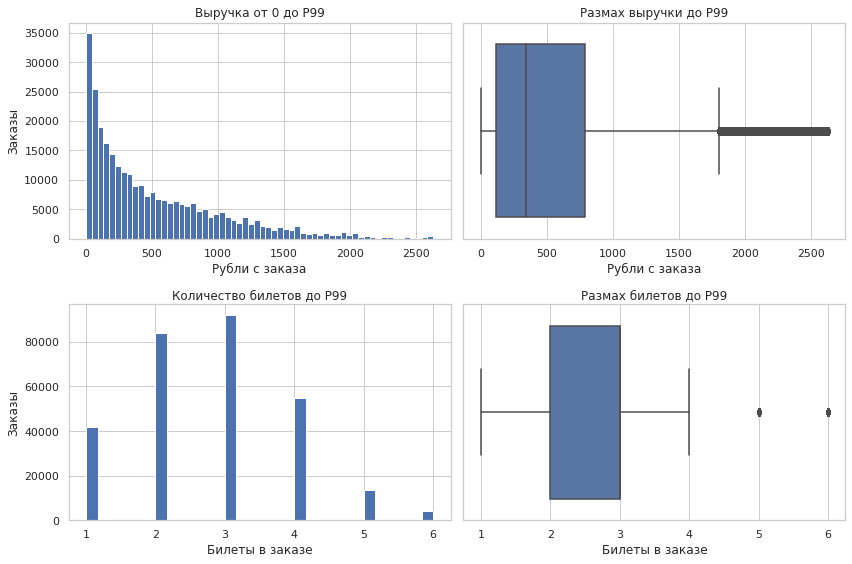

In [11]:
display(
    orders[['revenue_rub', 'tickets_count']]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
)
print('Нулевая выручка:', (orders['revenue_rub'] == 0).sum())
print('Отрицательная выручка:', (orders['revenue_rub'] < 0).sum())
print('Нулевое или отрицательное число билетов:', (orders['tickets_count'] <= 0).sum())

revenue_plot_max = orders['revenue_rub'].quantile(0.99)
tickets_plot_max = orders['tickets_count'].quantile(0.99)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].hist(orders.loc[orders['revenue_rub'].between(0, revenue_plot_max), 'revenue_rub'], bins=60)
axes[0, 0].set(title='Выручка от 0 до P99', xlabel='Рубли с заказа', ylabel='Заказы')
sns.boxplot(x=orders.loc[orders['revenue_rub'].between(0, revenue_plot_max), 'revenue_rub'], ax=axes[0, 1])
axes[0, 1].set(title='Размах выручки до P99', xlabel='Рубли с заказа')
axes[1, 0].hist(orders.loc[orders['tickets_count'].le(tickets_plot_max), 'tickets_count'], bins=30)
axes[1, 0].set(title='Количество билетов до P99', xlabel='Билеты в заказе', ylabel='Заказы')
sns.boxplot(x=orders.loc[orders['tickets_count'].le(tickets_plot_max), 'tickets_count'], ax=axes[1, 1])
axes[1, 1].set(title='Размах билетов до P99', xlabel='Билеты в заказе')
plt.tight_layout()
plt.show()

Отфильтруем верхний хвост выручки по 99-му перцентилю, как указано в задании.
Нули и отрицательную выручку сохраняем: без дополнительных сведений нельзя
утверждать, что это ошибка. Исходная таблица `orders` остаётся без фильтрации.
На графиках выше показан диапазон до P99 ради читаемости. Полные минимум, максимум и перцентили остаются в таблице; сами строки перед фильтрацией не удалялись.

In [12]:
p99_threshold = orders['revenue_rub'].quantile(0.99)
clean = orders[orders['revenue_rub'] <= p99_threshold].copy()

print('Порог P99:', round(p99_threshold, 2), 'руб.')
print('Заказов до фильтрации:', len(orders))
print('Заказов после фильтрации:', len(clean))
print('Удалено заказов:', len(orders) - len(clean))
print('  из них выше P99:', orders['revenue_rub'].gt(p99_threshold).sum())
print('  из них без рублёвой выручки:', orders['revenue_rub'].isna().sum())
print('Доля удалённых заказов: {:.2%}'.format(1 - len(clean) / len(orders)))
print('Пользователей до фильтрации:', orders['user_id'].nunique())
print('Пользователей после фильтрации:', clean['user_id'].nunique())
print('Исключено пользователей:', orders['user_id'].nunique() - clean['user_id'].nunique())

Порог P99: 2628.42 руб.
Заказов до фильтрации: 290611
Заказов после фильтрации: 287786
Удалено заказов: 2825
  из них выше P99: 2825
  из них без рублёвой выручки: 0
Доля удалённых заказов: 0.97%
Пользователей до фильтрации: 21933
Пользователей после фильтрации: 21854
Исключено пользователей: 79


**Промежуточный вывод.** Выручка приведена к рублям, проверены пропуски и категории,
выполнена нормализация названий операторов. Крупные заказы выше P99 исключены
из дальнейшего анализа. Количество билетов и необычную выручку дополнительно
не фильтруем. Объём удалённых данных показан выше.

**Результат запуска.** Из 290 611 заказов исключены 2 825 (0,97%) выше порога 2 628,42 руб.; пользователей стало 21 854 вместо 21 933 — на 79 меньше. Пропусков курса у 5 069 заказов в тенге нет. Нулевые и отрицательные значения выручки оставлены в анализе.

---

### 3. Создание профиля пользователя

В будущем отдел маркетинга планирует создать модель для прогнозирования возврата пользователей. Поэтому сейчас они просят вас построить агрегированные признаки, описывающие поведение и профиль каждого пользователя.

---

**Задача 3.1.** Постройте профиль пользователя — для каждого пользователя найдите:

- дату первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- билетного партнёра, к которому обращались при первом заказе;
- жанр первого посещённого мероприятия (используйте поле `event_type_main`);
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее количество билетов в заказе;
- среднее время между заказами.

После этого добавьте два бинарных признака:

- `is_two` — совершил ли пользователь 2 и более заказа;
- `is_five` — совершил ли пользователь 5 и более заказов.

**Рекомендация:** перед тем как строить профиль, отсортируйте данные по времени совершения заказа.

---


Функция ниже собирает профиль пользователя. Сначала сортируем заказы по времени,
затем берём признаки из одной строки первого заказа. После удаления выбросов
пересчитываем интервалы между оставшимися заказами. Покупки в один день дают ноль,
у пользователя с одной покупкой средний интервал не определён.

In [13]:
def build_profiles(data, end_date):
    data = data.sort_values(['user_id', 'order_ts', 'order_id']).copy()
    data['days_since_prev_clean'] = data.groupby('user_id')['order_dt'].diff().dt.days.astype('Int64')

    profiles = data.groupby('user_id').agg(
        first_order_dt=('order_dt', 'min'),
        last_order_dt=('order_dt', 'max'),
        total_orders=('order_id', 'nunique'),
        avg_revenue_rub=('revenue_rub', 'mean'),
        avg_tickets_count=('tickets_count', 'mean'),
        avg_interval_days=('days_since_prev_clean', 'mean'),
    )

    first_orders = data.drop_duplicates('user_id').set_index('user_id')
    first_features = first_orders[
        ['device_type_canonical', 'region_name', 'service_name', 'event_type_main']
    ].rename(
        columns={
            'device_type_canonical': 'first_device',
            'region_name': 'first_region',
            'service_name': 'first_service',
            'event_type_main': 'first_event_type',
        }
    )
    profiles = profiles.join(first_features).reset_index()
    profiles['is_two'] = profiles['total_orders'] >= 2
    profiles['is_five'] = profiles['total_orders'] >= 5
    profiles['first_weekday'] = profiles['first_order_dt'].dt.dayofweek
    profiles['cohort_month'] = profiles['first_order_dt'].dt.to_period('M').astype(str)
    profiles['observation_days'] = (end_date - profiles['first_order_dt']).dt.days
    profiles['activity_span_days'] = (
        profiles['last_order_dt'] - profiles['first_order_dt']
    ).dt.days
    profiles['order_group'] = pd.cut(
        profiles['total_orders'], bins=[0, 1, 4, np.inf], labels=['1', '2–4', '5+']
    )
    return data, profiles


ordered_clean, profiles = build_profiles(clean, orders['order_dt'].max())
profiles.head()

,user_id,first_order_dt,last_order_dt,total_orders,avg_revenue_rub,avg_tickets_count,avg_interval_days,first_device,first_region,first_service,first_event_type,is_two,is_five,first_weekday,cohort_month,observation_days,activity_span_days,order_group
0,0002849b70a3ce2,2024-08-20,2024-08-20,1,1521.94,4.00,<NA>,mobile,Каменевский регион,край билетов,театр,False,False,1,2024-08,72,0,1
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,2,774.01,3.00,75.00,mobile,Каменевский регион,мой билет,выставки,True,False,1,2024-07,100,75,2–4
2,000898990054619,2024-07-13,2024-10-23,3,767.21,2.67,51.00,mobile,Североярская область,лови билет!,другое,True,False,5,2024-07,110,102,2–4
3,00096d1f542ab2b,2024-08-15,2024-08-15,1,917.83,4.00,<NA>,desktop,Каменевский регион,край билетов,театр,False,False,3,2024-08,77,0,1
4,000a55a418c128c,2024-09-29,2024-10-15,2,61.31,1.50,16.00,mobile,Поленовский край,лучшие билеты,театр,True,False,6,2024-09,32,16,2–4


---

**Задача 3.2.** Прежде чем проводить исследовательский анализ данных и делать выводы, важно понять, с какими данными вы работаете: насколько они репрезентативны и нет ли в них аномалий.

Используя данные о профилях пользователей, рассчитайте:

- общее число пользователей в выборке;
- среднюю выручку с одного заказа;
- долю пользователей, совершивших 2 и более заказа;
- долю пользователей, совершивших 5 и более заказов.

Также изучите статистические показатели:

- по общему числу заказов;
- по среднему числу билетов в заказе;
- по среднему количеству дней между покупками.

По результатам оцените данные: достаточно ли их по объёму, есть ли аномальные значения в данных о количестве заказов и среднем количестве билетов?

Если вы найдёте аномальные значения, опишите их и примите обоснованное решение о том, как с ними поступить:

- Оставить и учитывать их при анализе?
- Отфильтровать данные по какому-то значению, например, по 95-му или 99-му перцентилю?

Если вы проведёте фильтрацию, то вычислите объём отфильтрованных данных и выведите статистические показатели по обновлённому датасету.

**Общая статистика профилей** Возвратом считаем второй и последующий заказ в выбранном периоде после очистки.
Средняя выручка по всем заказам и среднее пользовательских средних — разные
показатели: во втором случае каждый пользователь имеет одинаковый вес.

In [14]:
print('Пользователей:', len(profiles))
print('Заказов:', profiles['total_orders'].sum())
print(
    'Средняя выручка по всем заказам: {:.2f} руб.'.format(clean['revenue_rub'].mean())
)
print(
    'Среднее пользовательских средних: {:.2f} руб.'.format(
        profiles['avg_revenue_rub'].mean()
    )
)
print('Доля пользователей с 2+ заказами: {:.1%}'.format(profiles['is_two'].mean()))
print('Доля пользователей с 5+ заказами: {:.1%}'.format(profiles['is_five'].mean()))
print('Одна строка профиля на пользователя:', len(profiles) == profiles['user_id'].nunique())
print('Первые интервалы после фильтрации пустые:', ordered_clean.loc[ordered_clean.groupby('user_id').cumcount().eq(0), 'days_since_prev_clean'].isna().sum())

Пользователей: 21854
Заказов: 287786
Средняя выручка по всем заказам: 518.03 руб.
Среднее пользовательских средних: 544.40 руб.
Доля пользователей с 2+ заказами: 61.7%
Доля пользователей с 5+ заказами: 29.0%
Одна строка профиля на пользователя: True
Первые интервалы после фильтрации пустые: 21854


,count,mean,std,min,50%,90%,95%,99%,max
total_orders,21854.00,13.17,121.67,1.00,2.00,15.00,31.35,152.00,10181.00
avg_revenue_rub,21854.00,544.40,431.61,-10.77,467.28,1110.55,1371.46,1970.31,2628.42
avg_tickets_count,21854.00,2.74,0.91,1.00,2.75,4.00,4.00,5.00,11.00
avg_interval_days,13486.00,15.88,22.27,0.00,8.07,41.50,61.50,112.00,148.00
observation_days,21854.00,82.05,48.16,0.00,83.00,146.00,150.00,152.00,152.00
activity_span_days,21854.00,39.38,52.54,0.00,0.00,132.00,143.00,151.00,152.00


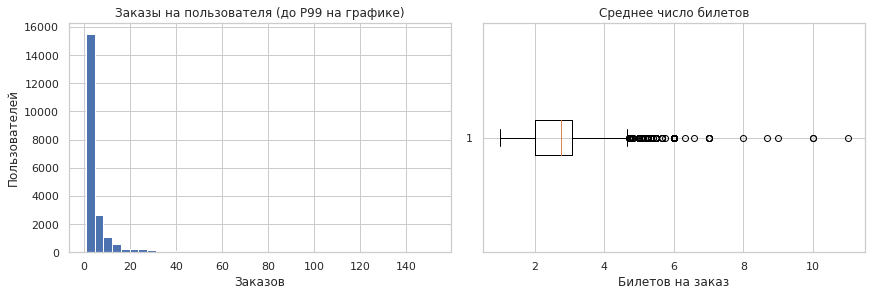

Максимум заказов у пользователя: 10181
P99 числа заказов: 152.0


In [15]:
profile_stats = (
    profiles[
        [
            'total_orders',
            'avg_revenue_rub',
            'avg_tickets_count',
            'avg_interval_days',
            'observation_days',
            'activity_span_days',
        ]
    ]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .T
)
display(profile_stats)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax[0].hist(
    profiles.loc[
        profiles.total_orders <= profiles.total_orders.quantile(0.99), "total_orders"
    ],
    bins=40,
)
ax[0].set(
    title='Заказы на пользователя (до P99 на графике)',
    xlabel='Заказов',
    ylabel='Пользователей',
)
ax[1].boxplot(profiles.avg_tickets_count.dropna(), vert=False)
ax[1].set(title='Среднее число билетов', xlabel='Билетов на заказ')
plt.show()
print('Максимум заказов у пользователя:', profiles['total_orders'].max())
print('P99 числа заказов:', profiles['total_orders'].quantile(0.99))

**Промежуточный вывод.** Профиль содержит число заказов, среднюю выручку и число
билетов, интервалы и признаки первого заказа. Пользователей с очень большим числом
покупок дополнительно не удаляем: по одному количеству нельзя доказать ошибку.
Такие наблюдения могут влиять на средние, поэтому рядом рассматриваем медианы.

**Результат запуска.** Получено 21 854 профиля по 287 786 заказам. Доля пользователей с 2+ заказами — 61,7%, с 5+ — 29,0%. Максимум 10 181 заказ у пользователя требует отдельной проверки, но одного числа недостаточно, чтобы объявить записи ошибкой.

---

### 4. Исследовательский анализ данных

Следующий этап — исследование признаков, влияющих на возврат пользователей, то есть на совершение повторного заказа. Для этого используйте профили пользователей.



#### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

Исследуйте признаки, описывающие первый заказ пользователя, и выясните, влияют ли они на вероятность возвращения пользователя.

---

**Задача 4.1.1.** Изучите распределение пользователей по признакам.

- Сгруппируйте пользователей:
    - по типу их первого мероприятия;
    - по типу устройства, с которого совершена первая покупка;
    - по региону проведения мероприятия из первого заказа;
    - по билетному оператору, продавшему билеты на первый заказ.
- Подсчитайте общее количество пользователей в каждом сегменте и их долю в разрезе каждого признака. Сегмент — это группа пользователей, объединённых определённым признаком, то есть объединённые принадлежностью к категории. Например, все клиенты, сделавшие первый заказ с мобильного телефона, — это сегмент.
- Ответьте на вопрос: равномерно ли распределены пользователи по сегментам или есть выраженные «точки входа» — сегменты с наибольшим числом пользователей?

---


**Распределение пользователей по сегментам**
Сначала определим простую функцию для расчёта числа пользователей, их доли в выборке
и доли повторных покупателей. Функция используется в следующих разделах.

In [16]:
def segment_table(data, field):
    result = (
        data.groupby(field, observed=True, dropna=False)
        .agg(users=('user_id', 'size'), returning_users=('is_two', 'sum'))
        .reset_index()
    )
    result['share_users_pct'] = result['users'] / len(data) * 100
    result['return_pct'] = result['returning_users'] / result['users'] * 100
    return result.sort_values('users', ascending=False).reset_index(drop=True)

Тип мероприятия — групп: 7


,first_event_type,users,returning_users,share_users_pct,return_pct
0,концерты,9643,5994,44.12,62.16
1,другое,5490,3299,25.12,60.09
2,театр,4289,2737,19.63,63.81
3,стендап,1118,684,5.12,61.18
4,спорт,801,450,3.67,56.18


Устройство — групп: 2


,first_device,users,returning_users,share_users_pct,return_pct
0,mobile,18108,11084,82.86,61.21
1,desktop,3746,2402,17.14,64.12


Регион — групп: 81


,first_region,users,returning_users,share_users_pct,return_pct
0,Каменевский регион,7159,4495,32.76,62.79
1,Североярская область,3799,2436,17.38,64.12
2,Широковская область,1237,803,5.66,64.92
3,Озернинский край,678,376,3.10,55.46
4,Малиновоярский округ,529,298,2.42,56.33


Оператор — групп: 34


,first_service,users,returning_users,share_users_pct,return_pct
0,билеты без проблем,5223,3170,23.90,60.69
1,мой билет,2992,1830,13.69,61.16
2,лови билет!,2848,1750,13.03,61.45
3,билеты в руки,2594,1640,11.87,63.22
4,облачко,2194,1351,10.04,61.58


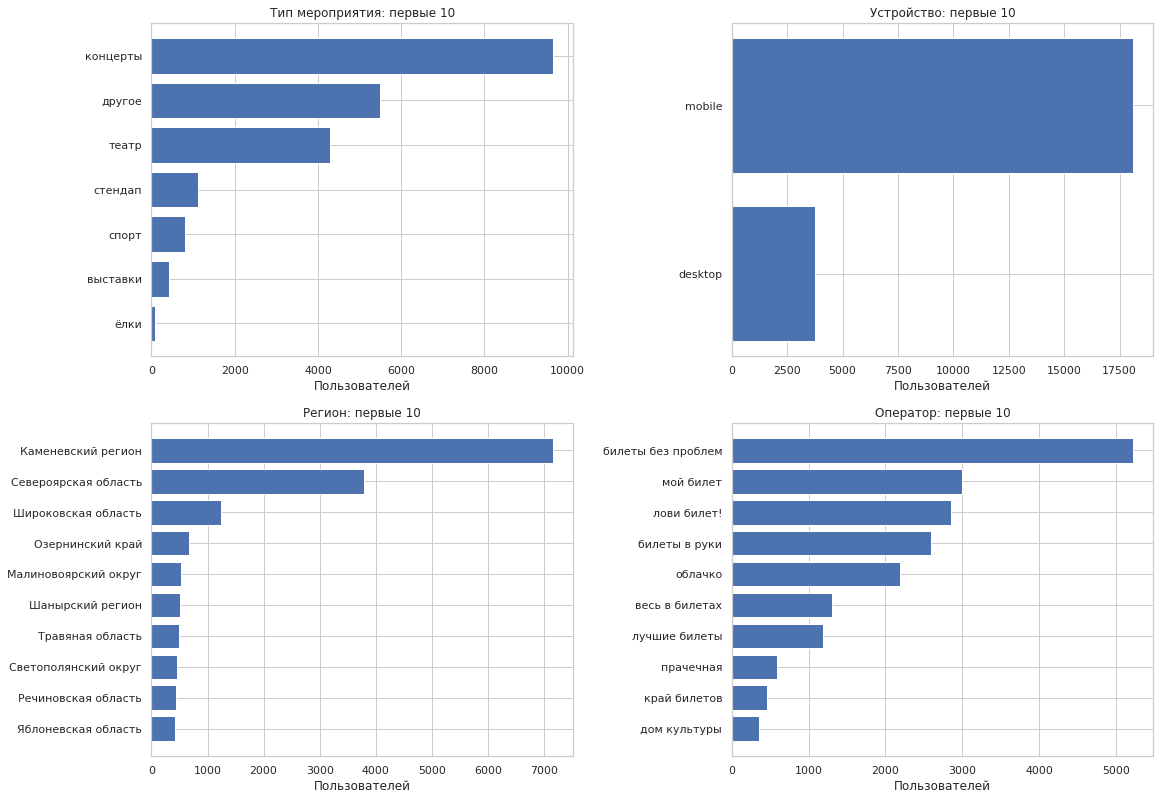

Крупнейшие сегменты показаны на графиках. Размеры групп различаются.


In [17]:
segment_fields = {
    'first_event_type': 'Тип мероприятия',
    'first_device': 'Устройство',
    'first_region': 'Регион',
    'first_service': 'Оператор',
}
segments = {}
for field in segment_fields:
    segments[field] = segment_table(profiles, field)
    print(segment_fields[field], '— групп:', len(segments[field]))
    display(segments[field].head(5))
fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)
for ax, (field, title) in zip(axes.flat, segment_fields.items()):
    top = segments[field].head(10).iloc[::-1]
    ax.barh(top[field].astype(str), top.users)
    ax.set(title=f'{title}: первые 10', xlabel='Пользователей')
plt.show()
print('Крупнейшие сегменты показаны на графиках. Размеры групп различаются.')

---

**Задача 4.1.2.** Проанализируйте возвраты пользователей:

- Для каждого сегмента вычислите долю пользователей, совершивших два и более заказа.
- Визуализируйте результат подходящим графиком. Если сегментов слишком много, то поместите на график только 10 сегментов с наибольшим количеством пользователей. Такое возможно с сегментами по региону и по билетному оператору.
- Ответьте на вопросы:
    - Какие сегменты пользователей чаще возвращаются на Яндекс Афишу?
    - Наблюдаются ли успешные «точки входа» — такие сегменты, в которых пользователи чаще совершают повторный заказ, чем в среднем по выборке?

При интерпретации результатов учитывайте размер сегментов: если в сегменте мало пользователей (например, десятки), то доли могут быть нестабильными и недостоверными, то есть показывать широкую вариацию значений.

---


Сравним долю пользователей с двумя и более заказами с общим уровнем.
Для регионов и операторов показываем 10 крупнейших групп по числу пользователей.
Порог 100 пользователей в текстовом сравнении — ориентир для отбора крупных групп,
а не гарантия статистической достоверности.

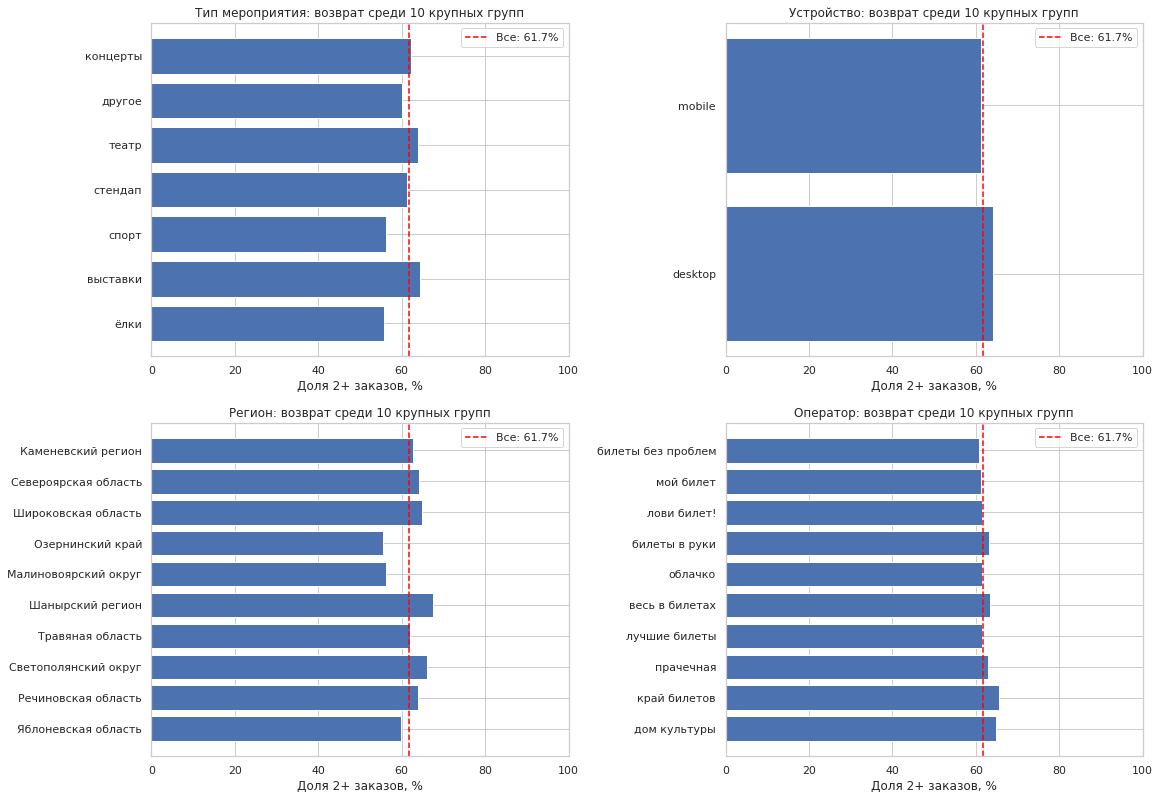

Тип мероприятия: среди групп ≥100 пользователей доля 2+ от спорт — 450/801 = 56.2% до выставки — 269/418 = 64.4%; все пользователи — 61.7%.
Устройство: среди групп ≥100 пользователей доля 2+ от mobile — 11084/18108 = 61.2% до desktop — 2402/3746 = 64.1%; все пользователи — 61.7%.
Регион: среди групп ≥100 пользователей доля 2+ от Глиногорская область — 118/219 = 53.9% до Горицветская область — 173/255 = 67.8%; все пользователи — 61.7%.
Оператор: среди групп ≥100 пользователей доля 2+ от яблоко — 172/320 = 53.8% до show_ticket — 108/163 = 66.3%; все пользователи — 61.7%.
Общая доля повторных покупателей: 61.7%
Малые сегменты нужно сравнивать осторожно: их доли менее устойчивы.


In [18]:
overall_return = profiles.is_two.mean() * 100
fig, axes = plt.subplots(2, 2, figsize=(16, 11), constrained_layout=True)
for ax, (field, title) in zip(axes.flat, segment_fields.items()):
    top = segments[field].head(10).iloc[::-1]
    ax.barh(top[field].astype(str), top.return_pct)
    ax.axvline(
        overall_return, color='red', linestyle='--', label=f'Все: {overall_return:.1f}%'
    )
    ax.set(
        title=f'{title}: возврат среди 10 крупных групп',
        xlabel='Доля 2+ заказов, %',
        xlim=(0, 100),
    )
    ax.legend()
plt.show()
for field, title in segment_fields.items():
    stable = segments[field].query('users >= 100')
    if len(stable):
        top = stable.loc[stable.return_pct.idxmax()]
        low = stable.loc[stable.return_pct.idxmin()]
        print(
            f'{title}: среди групп ≥100 пользователей доля 2+ от {low[field]} — {int(low.returning_users)}/{int(low.users)} = {low.return_pct:.1f}% до {top[field]} — {int(top.returning_users)}/{int(top.users)} = {top.return_pct:.1f}%; все пользователи — {overall_return:.1f}%.'
        )
print('Общая доля повторных покупателей: {:.1f}%'.format(overall_return))
print('Малые сегменты нужно сравнивать осторожно: их доли менее устойчивы.')

---

**Задача 4.1.3.** Опираясь на выводы из задач выше, проверьте продуктовые гипотезы:

- **Гипотеза 1.** Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
- **Гипотеза 2.** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.

---

Активными считаем регионы из верхней четверти по числу пользователей первого заказа
(порог P75). Это описательное сравнение, а не статистический тест или доказательство причины.

,users,returning_users,share_users_pct,return_pct
first_event_type,,,,
спорт,801,450,3.67,56.18
концерты,9643,5994,44.12,62.16


,active_first_region,users,returning_users,return_pct
0,False,2871,1660,57.82
1,True,18983,11826,62.30


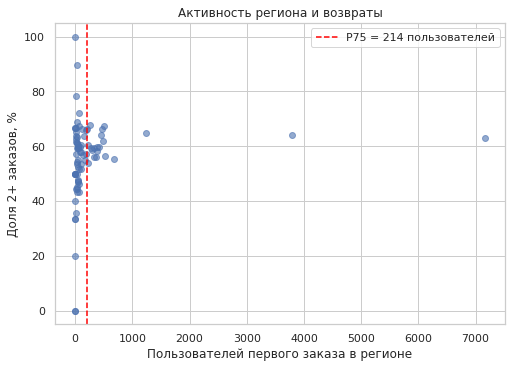

Разница долей: спорт минус концерты = -5.98 п.п.
Порог активного региона: 214.0 пользователей
Активных регионов: 21


In [19]:
event_hyp = (
    segments['first_event_type']
    .set_index('first_event_type')
    .loc[['спорт', 'концерты']]
)
display(event_hyp)
sport_pp = (
    event_hyp.loc['спорт', 'return_pct'] - event_hyp.loc['концерты', 'return_pct']
)
regions = segments['first_region'].copy()
active_cutoff = regions.users.quantile(0.75)
active_names = set(regions.loc[regions.users.ge(active_cutoff), 'first_region'])
profiles['active_first_region'] = profiles.first_region.isin(active_names)
region_hyp = (
    profiles.groupby('active_first_region')
    .agg(users=('user_id', 'size'), returning_users=('is_two', 'sum'))
    .reset_index()
)
region_hyp['return_pct'] = 100 * region_hyp.returning_users / region_hyp.users
display(region_hyp)
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
ax.scatter(regions.users, regions.return_pct, alpha=0.6)
ax.axvline(
    active_cutoff,
    color='red',
    linestyle='--',
    label=f'P75 = {active_cutoff:.0f} пользователей',
)
ax.set(
    xlabel='Пользователей первого заказа в регионе',
    ylabel='Доля 2+ заказов, %',
    title='Активность региона и возвраты',
)
ax.legend()
plt.show()
print('Разница долей: спорт минус концерты = {:.2f} п.п.'.format(sport_pp))
print('Порог активного региона:', active_cutoff, 'пользователей')
print('Активных регионов:', len(active_names))

In [20]:
sport_rate = event_hyp.loc['спорт', 'return_pct']
concert_rate = event_hyp.loc['концерты', 'return_pct']
if sport_rate > concert_rate:
    print('Гипотеза 1 согласуется с данными: доля возвратов у спорта выше.')
else:
    print(
        'Гипотеза 1 не подтверждается описательным сравнением: у спорта доля не выше.'
    )

active_rate = region_hyp.loc[region_hyp['active_first_region'], 'return_pct'].iloc[0]
other_rate = region_hyp.loc[~region_hyp['active_first_region'], 'return_pct'].iloc[0]
print('Активные регионы: {:.2f}%; остальные: {:.2f}%.'.format(active_rate, other_rate))
if active_rate > other_rate:
    print('Гипотеза 2 согласуется с данными, но причинное влияние не установлено.')
else:
    print('Гипотеза 2 не подтверждается описательным сравнением.')

Гипотеза 1 не подтверждается описательным сравнением: у спорта доля не выше.
Активные регионы: 62.30%; остальные: 57.82%.
Гипотеза 2 согласуется с данными, но причинное влияние не установлено.


---

#### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа

Изучите количественные характеристики заказов пользователей, чтобы узнать среднюю выручку сервиса с заказа и количество билетов, которое пользователи обычно покупают.

Эти метрики важны не только для оценки выручки, но и для оценки вовлечённости пользователей. Возможно, пользователи с более крупными и дорогими заказами более заинтересованы в сервисе и поэтому чаще возвращаются.

---

**Задача 4.2.1.** Проследите связь между средней выручкой сервиса с заказа и повторными заказами.

- Постройте сравнительные гистограммы распределения средней выручки с билета (`avg_revenue_rub`):
    - для пользователей, совершивших один заказ;
    - для вернувшихся пользователей, совершивших 2 и более заказа.
- Ответьте на вопросы:
    - В каких диапазонах средней выручки концентрируются пользователи из каждой группы?
    - Есть ли различия между группами?

Текст на сером фоне:
    
**Рекомендация:**

1. Используйте одинаковые интервалы (`bins`) и прозрачность (`alpha`), чтобы визуально сопоставить распределения.
2. Задайте параметру `density` значение `True`, чтобы сравнивать форму распределений, даже если число пользователей в группах отличается.

---


`avg_revenue_rub` — средняя выручка **с заказа**, а не с билета. Сравним её распределение
для пользователей с одной и несколькими покупками. Интервалы гистограмм одинаковы,
`density=True` позволяет сравнить форму распределений при разном размере групп.

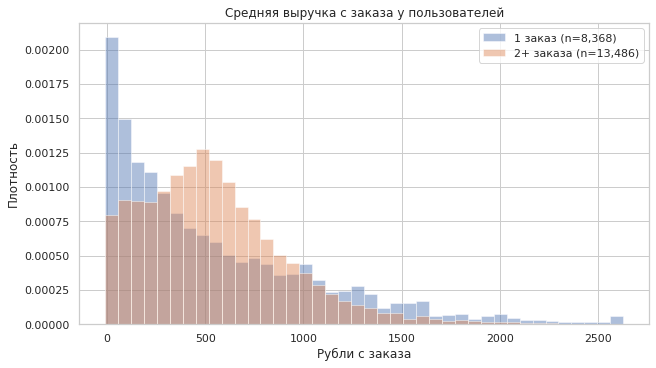

,group,users,mean,median
0,1,8368,545.30,378.03
1,2+,13486,543.84,497.62


Медиана для одного заказа: 378.03 руб.
Медиана для 2+ заказов: 497.62 руб.


In [21]:
rev_bounds = [profiles.avg_revenue_rub.min(), profiles.avg_revenue_rub.max()]
rev_bins = np.linspace(rev_bounds[0], rev_bounds[1], 41)
one = profiles.loc[profiles.total_orders.eq(1), 'avg_revenue_rub']
repeat = profiles.loc[profiles.total_orders.ge(2), 'avg_revenue_rub']
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
for values, label in [(one, '1 заказ'), (repeat, '2+ заказа')]:
    ax.hist(
        values,
        bins=rev_bins,
        density=True,
        alpha=0.45,
        label=f'{label} (n={len(values):,})',
    )
ax.set(
    title='Средняя выручка с заказа у пользователей',
    xlabel='Рубли с заказа',
    ylabel='Плотность',
)
ax.legend()
plt.show()
display(
    pd.DataFrame(
        {
            'group': ['1', '2+'],
            'users': [len(one), len(repeat)],
            'mean': [one.mean(), repeat.mean()],
            'median': [one.median(), repeat.median()],
        }
    )
)
print('Медиана для одного заказа: {:.2f} руб.'.format(one.median()))
print('Медиана для 2+ заказов: {:.2f} руб.'.format(repeat.median()))

---

**Задача 4.2.2.** Сравните распределение по средней выручке с заказа в двух группах пользователей:

- совершившие 2–4 заказа;
- совершившие 5 и более заказов.

Ответьте на вопрос: есть ли различия по значению средней выручки с заказа между пользователями этих двух групп?

---


Сравним две группы повторных покупателей. Наряду со средним используем медиану,
которая меньше зависит от крайних значений.

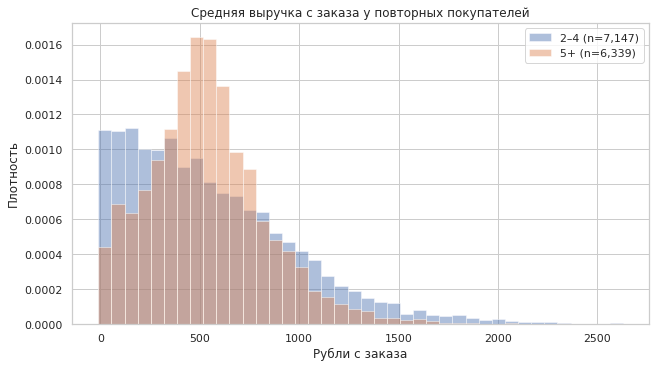

,group,users,mean,median
0,2–4,7147,551.57,471.27
1,5+,6339,535.12,513.56


Медиана для 2–4 заказов: 471.27 руб.
Медиана для 5+ заказов: 513.56 руб.


In [22]:
few = profiles.loc[profiles.total_orders.between(2, 4), 'avg_revenue_rub']
many = profiles.loc[profiles.total_orders.ge(5), 'avg_revenue_rub']
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
for values, label in [(few, '2–4'), (many, '5+')]:
    ax.hist(
        values,
        bins=rev_bins,
        density=True,
        alpha=0.45,
        label=f'{label} (n={len(values):,})',
    )
ax.set(
    title='Средняя выручка с заказа у повторных покупателей',
    xlabel='Рубли с заказа',
    ylabel='Плотность',
)
ax.legend()
plt.show()
display(
    pd.DataFrame(
        {
            'group': ['2–4', '5+'],
            'users': [len(few), len(many)],
            'mean': [few.mean(), many.mean()],
            'median': [few.median(), many.median()],
        }
    )
)
print('Медиана для 2–4 заказов: {:.2f} руб.'.format(few.median()))
print('Медиана для 5+ заказов: {:.2f} руб.'.format(many.median()))

---

**Задача 4.2.3.** Проанализируйте влияние среднего количества билетов в заказе на вероятность повторной покупки.

- Изучите распределение пользователей по среднему количеству билетов в заказе (`avg_tickets_count`) и опишите основные наблюдения.
- Разделите пользователей на несколько сегментов по среднему количеству билетов в заказе:
    - от 1 до 2 билетов;
    - от 2 до 3 билетов;
    - от 3 до 5 билетов;
    - от 5 и более билетов.
- Для каждого сегмента подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы.
- Ответьте на вопросы:
    - Как распределены пользователи по сегментам — равномерно или сконцентрировано?
    - Есть ли сегменты с аномально высокой или низкой долей повторных покупок?

---

Интервалы не пересекаются: от 1 включительно до 2, от 2 до 3, от 3 до 5,
от 5 включительно и выше. Значения меньше 1 рассматриваем отдельно, если они есть.

,users,returning_users,share_users_pct,return_pct
ticket_segment,,,,
<1,NaN,NaN,NaN,NaN
"[1,2)",2419.00,1241.00,11.07,51.30
"[2,3)",9706.00,7197.00,44.41,74.15
"[3,5)",9068.00,4924.00,41.49,54.30
"[5,∞)",661.00,124.00,3.02,18.76


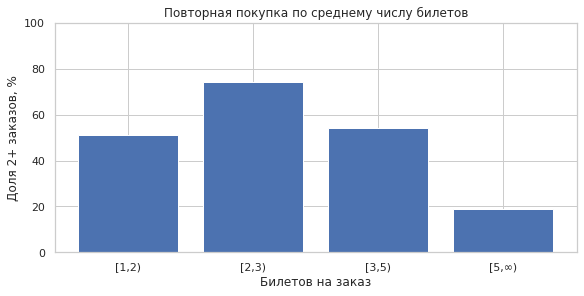

Наименьшая доля возвратов: [5,∞)
Наибольшая доля возвратов: [2,3)


In [23]:
ticket_bins = [-np.inf, 1, 2, 3, 5, np.inf]
ticket_labels = ['<1', '[1,2)', '[2,3)', '[3,5)', '[5,∞)']
profiles['ticket_segment'] = pd.cut(
    profiles.avg_tickets_count, bins=ticket_bins, labels=ticket_labels, right=False
)
ticket_table = (
    segment_table(profiles, 'ticket_segment')
    .set_index('ticket_segment')
    .reindex(ticket_labels)
)
display(ticket_table)
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.bar(ticket_table.index.astype(str), ticket_table.return_pct)
ax.set(
    title='Повторная покупка по среднему числу билетов',
    xlabel='Билетов на заказ',
    ylabel='Доля 2+ заказов, %',
    ylim=(0, 100),
)
plt.show()
populated_tickets = ticket_table.loc[ticket_table.users.gt(0)]
ticket_low = populated_tickets.return_pct.idxmin()
ticket_high = populated_tickets.return_pct.idxmax()
print('Наименьшая доля возвратов:', ticket_low)
print('Наибольшая доля возвратов:', ticket_high)

---

#### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки

Изучите временные параметры, связанные с первым заказом пользователей:

- день недели первой покупки;
- время с момента первой покупки — лайфтайм;
- средний интервал между покупками пользователей с повторными заказами.

---

**Задача 4.3.1.** Проанализируйте, как день недели, в которой была совершена первая покупка, влияет на поведение пользователей.

- По данным даты первого заказа выделите день недели.
- Для каждого дня недели подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы. Результаты визуализируйте.
- Ответьте на вопрос: влияет ли день недели, в которую совершена первая покупка, на вероятность возврата клиента?

---


Время наблюдения — число дней от первого заказа до конца выборки.
Длительность активности — число дней между первым и последним заказами.
Эти величины различаются. У поздно пришедших пользователей меньше времени
для повторной покупки, поэтому дополнительно посмотрим месяцы первого заказа.

,users,returning_users,share_users_pct,return_pct
Пн,2943,1860,13.47,63.20
Вт,3189,1979,14.59,62.06
Ср,3072,1916,14.06,62.37
Чт,3120,1857,14.28,59.52
Пт,3261,1952,14.92,59.86
Сб,3459,2222,15.83,64.24
Вс,2810,1700,12.86,60.50


,cohort_month,users,returning_users,share_users_pct,return_pct,mean_observation_days
0,2024-06,6203,5053,28.38,81.46,140.71
3,2024-07,3776,2603,17.28,68.94,107.64
4,2024-08,3468,2059,15.87,59.37,76.40
2,2024-09,4071,2141,18.63,52.59,45.28
1,2024-10,4336,1630,19.84,37.59,14.86


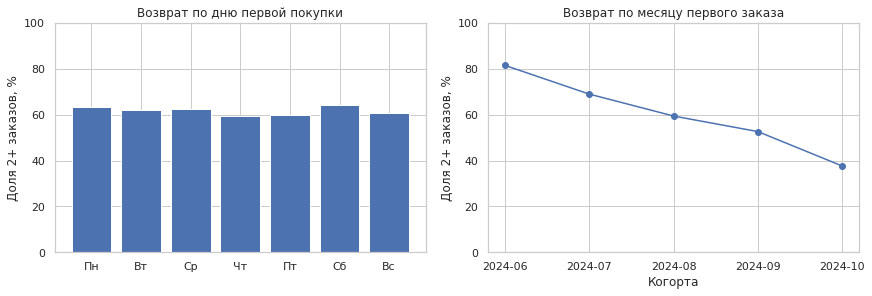

Наименьшая доля возвратов по дням недели: Чт
Наибольшая доля возвратов по дням недели: Сб
Медиана времени наблюдения: 83.0 дней
Медиана длительности активности: 0.0 дней


In [24]:
weekday_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
weekday_table = (
    segment_table(profiles, 'first_weekday')
    .set_index('first_weekday')
    .reindex(range(7))
)
weekday_table.index = weekday_names
cohort_table = segment_table(profiles, 'cohort_month').sort_values('cohort_month')
cohort_table['mean_observation_days'] = cohort_table.cohort_month.map(
    profiles.groupby('cohort_month').observation_days.mean()
)
display(weekday_table, cohort_table)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].bar(weekday_names, weekday_table.return_pct)
axes[0].set(
    title='Возврат по дню первой покупки', ylabel='Доля 2+ заказов, %', ylim=(0, 100)
)
axes[1].plot(cohort_table.cohort_month, cohort_table.return_pct, marker='o')
axes[1].set(
    title='Возврат по месяцу первого заказа',
    xlabel='Когорта',
    ylabel='Доля 2+ заказов, %',
    ylim=(0, 100),
)
plt.show()
weekday_min = weekday_table.return_pct.idxmin()
weekday_max = weekday_table.return_pct.idxmax()
print('Наименьшая доля возвратов по дням недели:', weekday_min)
print('Наибольшая доля возвратов по дням недели:', weekday_max)
print('Медиана времени наблюдения:', profiles['observation_days'].median(), 'дней')
print(
    'Медиана длительности активности:', profiles['activity_span_days'].median(), 'дней'
)

---

**Задача 4.3.2.** Изучите, как средний интервал между заказами влияет на удержание клиентов.

- Рассчитайте среднее время между заказами для двух групп пользователей:
    - совершившие 2–4 заказа;
    - совершившие 5 и более заказов.
- Исследуйте, как средний интервал между заказами влияет на вероятность повторного заказа, и сделайте выводы.

---


Сравним пользователей с 2–4 и с 5+ заказами. Средний интервал известен только
повторным покупателям, поэтому по нему нельзя оценить вероятность первого возврата
для тех, кто ещё не сделал вторую покупку.

,users,mean_interval,median_interval,mean_observation_days,mean_activity_span_days
order_group,,,,,
2–4,7147,21.41,9.00,77.27,33.85
5+,6339,9.64,7.83,114.40,97.61


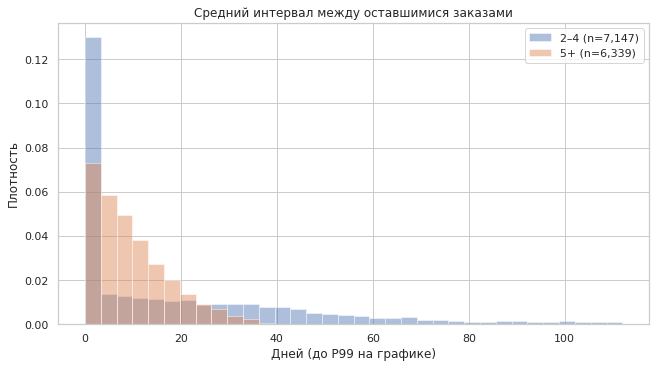

Сравниваем интервалы только у повторных покупателей.
Медиана интервала у 2–4 заказов: 9.0 дня
Медиана интервала у 5+ заказов: 7.8 дня


In [25]:
interval_summary = (
    profiles.loc[profiles.total_orders.ge(2)]
    .groupby('order_group', observed=True)
    .agg(
        users=('user_id', 'size'),
        mean_interval=('avg_interval_days', 'mean'),
        median_interval=('avg_interval_days', 'median'),
        mean_observation_days=('observation_days', 'mean'),
        mean_activity_span_days=('activity_span_days', 'mean'),
    )
)
display(interval_summary)
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
upper_interval = profiles.avg_interval_days.quantile(0.99)
interval_bins = np.linspace(0, upper_interval, 35)
for group in ['2–4', '5+']:
    vals = profiles.loc[profiles.order_group.eq(group), 'avg_interval_days'].dropna()
    ax.hist(
        vals,
        bins=interval_bins,
        density=True,
        alpha=0.45,
        label=f'{group} (n={len(vals):,})',
    )
ax.set(
    title='Средний интервал между оставшимися заказами',
    xlabel='Дней (до P99 на графике)',
    ylabel='Плотность',
)
ax.legend()
plt.show()
print('Сравниваем интервалы только у повторных покупателей.')
print(
    'Медиана интервала у 2–4 заказов: {:.1f} дня'.format(
        interval_summary.loc['2–4', 'median_interval']
    )
)
print(
    'Медиана интервала у 5+ заказов: {:.1f} дня'.format(
        interval_summary.loc['5+', 'median_interval']
    )
)

---

#### 4.4. Корреляционный анализ количества покупок и признаков пользователя

Изучите, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок. Для этого используйте универсальный коэффициент корреляции `phi_k`, который позволяет анализировать как числовые, так и категориальные признаки.

---

**Задача 4.4.1:** Проведите корреляционный анализ:
- Рассчитайте коэффициент корреляции `phi_k` между признаками профиля пользователя и числом заказов (`total_orders`). При необходимости используйте параметр `interval_cols` для определения интервальных данных.
- Проанализируйте полученные результаты. Если полученные значения будут близки к нулю, проверьте разброс данных в `total_orders`. Такое возможно, когда в данных преобладает одно значение: в таком случае корреляционный анализ может показать отсутствие связей. Чтобы этого избежать, выделите сегменты пользователей по полю `total_orders`, а затем повторите корреляционный анализ. Выделите такие сегменты:
    - 1 заказ;
    - от 2 до 4 заказов;
    - от 5 и выше.
- Визуализируйте результат корреляции с помощью тепловой карты.
- Ответьте на вопрос: какие признаки наиболее связаны с количеством заказов?

---

`phi_k` позволяет сравнивать числовые и категориальные признаки. Укажем числовые
поля в `interval_cols`. Идентификаторы не включаем. Производные от числа заказов
признаки `is_two` и `is_five` тоже исключаем: их связь с числом заказов очевидна
по определению.

,total_orders
total_orders,1.00
first_region,0.13
first_service,0.10
activity_span_days,0.10
observation_days,0.05
first_event_type,0.00
first_device,0.00
avg_revenue_rub,0.00
avg_tickets_count,0.00
avg_interval_days,0.00


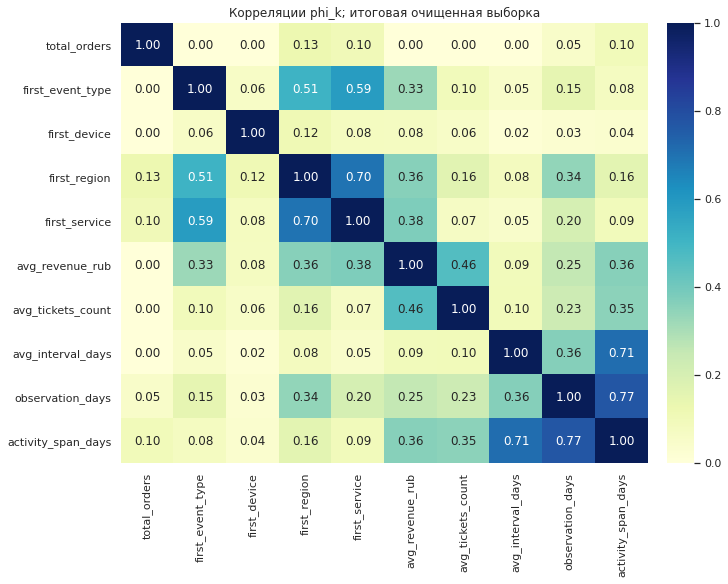

Самая сильная связь среди признаков первого заказа: first_region
Значение phi_k: 0.127


In [26]:
correlation_cols = [
    'total_orders',
    'first_event_type',
    'first_device',
    'first_region',
    'first_service',
    'avg_revenue_rub',
    'avg_tickets_count',
    'avg_interval_days',
    'observation_days',
    'activity_span_days',
]
interval_cols = [
    'total_orders',
    'avg_revenue_rub',
    'avg_tickets_count',
    'avg_interval_days',
    'observation_days',
    'activity_span_days',
]
phi = profiles[correlation_cols].phik_matrix(
    interval_cols=interval_cols, njobs=1, verbose=False
)
display(phi[['total_orders']].sort_values('total_orders', ascending=False))
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
sns.heatmap(phi, cmap='YlGnBu', vmin=0, vmax=1, annot=True, fmt='.2f', ax=ax)
ax.set_title('Корреляции phi_k; итоговая очищенная выборка')
plt.show()
first_features = ['first_event_type', 'first_device', 'first_region', 'first_service']
best_first = phi.loc[first_features, 'total_orders'].idxmax()
print('Самая сильная связь среди признаков первого заказа:', best_first)
print('Значение phi_k:', round(phi.loc[best_first, 'total_orders'], 3))

Распределение числа заказов имеет длинный хвост. Поэтому дополнительно повторим
анализ для групп «1», «2–4», «5+», как предлагает задание. Само число заказов
из второго расчёта исключим, иначе сравнивали бы его с собственной группировкой.

,order_group
order_group,1.00
activity_span_days,0.73
observation_days,0.48
avg_interval_days,0.39
avg_tickets_count,0.39
avg_revenue_rub,0.33
first_region,0.13
first_service,0.09
first_event_type,0.04
first_device,0.02


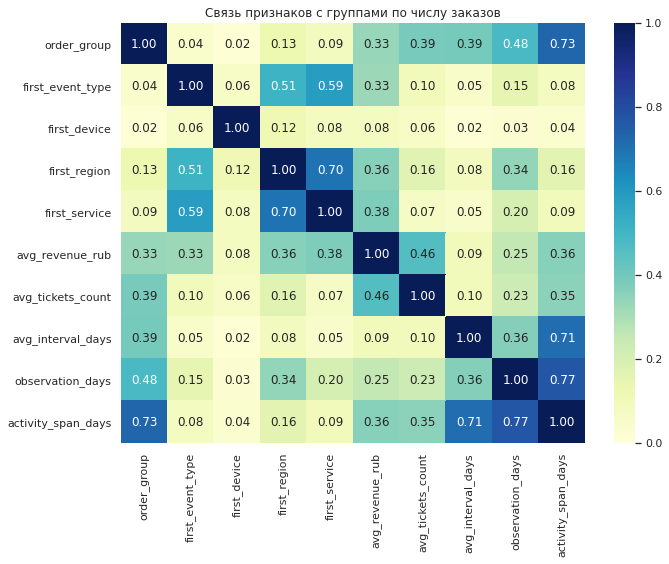

In [27]:
grouped_columns = ['order_group'] + [
    column for column in correlation_cols if column != 'total_orders'
]
grouped_intervals = [column for column in interval_cols if column != 'total_orders']

phi_grouped = profiles[grouped_columns].phik_matrix(
    interval_cols=grouped_intervals, njobs=1, verbose=False
)
display(phi_grouped[['order_group']].sort_values('order_group', ascending=False))

plt.figure(figsize=(10, 8))
sns.heatmap(phi_grouped, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1)
plt.title('Связь признаков с группами по числу заказов')
plt.tight_layout()
plt.show()

**Промежуточный вывод.** Сравним признаки по силе связи с количеством заказов
и его группами. Средняя выручка, билеты и интервалы рассчитаны по всей истории:
они описывают уже совершённые покупки и не подходят без изменений для прогноза
первого возврата. Корреляция сама по себе не доказывает причинную связь.

**Результат запуска.** Среди признаков первого заказа наиболее заметная связь с числом заказов у региона (`phi_k = 0,127`), но она слабая. Для групп «1», «2–4», «5+» сильнее всего связан размах активности  (`phi_k = 0,73`), который сам зависит от последующих покупок.

### 5. Общий вывод и рекомендации

В конце проекта напишите общий вывод и рекомендации: расскажите заказчику, на что нужно обратить внимание. В выводах кратко укажите:

- **Информацию о данных**, с которыми вы работали, и то, как они были подготовлены: например, расскажите о фильтрации данных, переводе тенге в рубли, фильтрации выбросов.
- **Основные результаты анализа.** Например, укажите:
    - Сколько пользователей в выборке? Как распределены пользователи по числу заказов? Какие ещё статистические показатели вы подсчитали важным во время изучения данных?
    - Какие признаки первого заказа связаны с возвратом пользователей?
    - Как связаны средняя выручка и количество билетов в заказе с вероятностью повторных покупок?
    - Какие временные характеристики влияют на удержание (день недели, интервалы между покупками)?
    - Какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок согласно результатам корреляционного анализа?
- Дополните выводы информацией, которая покажется вам важной и интересной. Следите за общим объёмом выводов — они должны быть компактными и ёмкими.

В конце предложите заказчику рекомендации о том, как именно действовать в его ситуации. Например, укажите, на какие сегменты пользователей стоит обратить внимание в первую очередь, а какие нуждаются в дополнительных маркетинговых усилиях.

In [28]:
top_operator = segments['first_service'].iloc[0]
print('После очистки осталось заказов:', len(ordered_clean))
print('Пользователей в анализе:', len(profiles))
print('Доля с 2+ заказами: {:.1%}'.format(profiles['is_two'].mean()))
print('Доля с 5+ заказами: {:.1%}'.format(profiles['is_five'].mean()))
print('Крупнейший оператор первого заказа:', top_operator['first_service'])
print('Разница возвратов спорт — концерты: {:.2f} п.п.'.format(sport_pp))
print(
    'Разница возвратов активные — остальные регионы: {:.2f} п.п.'.format(
        active_rate - other_rate
    )
)
print('Самый связанный с числом заказов признак первого заказа:', best_first)
print('Его phi_k:', round(phi.loc[best_first, 'total_orders'], 3))

После очистки осталось заказов: 287786
Пользователей в анализе: 21854
Доля с 2+ заказами: 61.7%
Доля с 5+ заказами: 29.0%
Крупнейший оператор первого заказа: билеты без проблем
Разница возвратов спорт — концерты: -5.98 п.п.
Разница возвратов активные — остальные регионы: 4.48 п.п.
Самый связанный с числом заказов признак первого заказа: first_region
Его phi_k: 0.127


In [29]:
print('Сравнение выручки:')
print('Медиана у пользователей с одним заказом: {:.2f} руб.'.format(one.median()))
print('Медиана у пользователей с 2+ заказами: {:.2f} руб.'.format(repeat.median()))
print('Медиана у пользователей с 2–4 заказами: {:.2f} руб.'.format(few.median()))
print('Медиана у пользователей с 5+ заказами: {:.2f} руб.'.format(many.median()))
print(
    '\nБилеты: наибольшая доля возвратов в сегменте',
    ticket_high,
    '— {:.1f}%.'.format(populated_tickets.loc[ticket_high, 'return_pct']),
)
print(
    'Дни недели: от {:.1f}% ({}) до {:.1f}% ({}).'.format(
        weekday_table.loc[weekday_min, 'return_pct'],
        weekday_min,
        weekday_table.loc[weekday_max, 'return_pct'],
        weekday_max,
    )
)
print(
    'Средний интервал у группы 2–4: {:.1f} дня.'.format(
        interval_summary.loc['2–4', 'mean_interval']
    )
)
print(
    'Средний интервал у группы 5+: {:.1f} дня.'.format(
        interval_summary.loc['5+', 'mean_interval']
    )
)

Сравнение выручки:
Медиана у пользователей с одним заказом: 378.03 руб.
Медиана у пользователей с 2+ заказами: 497.62 руб.
Медиана у пользователей с 2–4 заказами: 471.27 руб.
Медиана у пользователей с 5+ заказами: 513.56 руб.

Билеты: наибольшая доля возвратов в сегменте [2,3) — 74.2%.
Дни недели: от 59.5% (Чт) до 64.2% (Сб).
Средний интервал у группы 2–4: 21.4 дня.
Средний интервал у группы 5+: 9.6 дня.


В ходе исследования проанализированы заказы Яндекс Афиши за период с 1 июня по 31 октября 2024 года. Цель — определить, какие особенности первого заказа и поведения пользователей связаны с повторными покупками.

**Подготовка данных.** Из базы выгружены 290 611 заказов от 21 933 пользователей. В выборку включены покупки с мобильных и десктопных устройств, заказы на фильмы исключены. Дубликатов заказов не обнаружено. Пропуски присутствовали только в интервале до предыдущей покупки и соответствовали первым заказам пользователей.

Выручка в тенге переведена в рубли по курсу на дату заказа с учётом номинала 100 тенге. Для ограничения влияния крупных заказов исключены значения выше 99-го перцентиля — 2 628,42 руб. Удалены 2 825 заказов, или 0,97% выборки. Нулевую и отрицательную выручку сохранили, поскольку без дополнительных сведений нельзя считать её ошибкой. После очистки осталось **287 786 заказов и 21 854 пользователя**.

**Общая характеристика пользователей.** Повторную покупку совершили **61,7% пользователей**, пять и более заказов — **29,0%**. Распределение по числу заказов:

- один заказ — 8 368 пользователей;
- от двух до четырёх — 7 147;
- пять и более — 6 339.

Средняя выручка с заказа после очистки составила **518,03 руб.** Медианное число заказов на пользователя — 2, среднее — 13,17. Значительное расхождение связано с длинным хвостом распределения: у одного пользователя зафиксирован 10 181 заказ. Такие профили требуют дополнительного изучения и могут заметно влиять на средние показатели.

**Первый заказ и возвращение на платформу.** Основные точки входа — концерты, на которые приходится 44,1% первых заказов пользователей, и мобильные устройства — 82,9%. При этом доля повторных покупателей среди пользователей с первым заказом с компьютера выше: **64,1% против 61,2%** у мобильных пользователей. Крупнейший оператор первого заказа — «Билеты без проблем», охватывающий 23,9% пользователей.

Гипотеза о более частом возвращении после первого спортивного мероприятия **не подтвердилась описательным сравнением**: повторные покупки совершили 56,18% таких пользователей против 62,16% покупателей концертов. Разница составила 5,98 процентного пункта в пользу концертов.

Гипотеза об активных регионах **согласуется с наблюдениями**. В регионах верхнего квартиля по числу пользователей доля повторных покупателей составила 62,30%, в остальных — 57,82%. Однако эти различия могут быть связаны с составом аудитории, предложением мероприятий и временем наблюдения.

**Выручка и количество билетов.** У вернувшихся пользователей медиана средней выручки с заказа выше: **497,62 руб. против 378,03 руб.** у пользователей с одной покупкой. При этом средние значения практически одинаковы — около 544–545 руб., поэтому однозначной зависимости «дороже заказ — выше вероятность возврата» не выявлено.

Наибольшая доля повторных покупателей наблюдается среди пользователей, приобретающих в среднем от 2 включительно до 3 билетов на заказ: **74,15%**. При среднем количестве от 5 билетов она составляет лишь **18,76%**. Таким образом, большие заказы по числу билетов не обязательно связаны с более частыми покупками.

**Временные характеристики.** Доля повторных покупателей различается по дню первой покупки: от 59,5% в четверг до 64,2% в субботу. Эти наблюдения не доказывают самостоятельного влияния дня недели.

Пользователи с пятью и более заказами покупают чаще: средний пользовательский интервал составляет **9,6 дня**, тогда как у группы с двумя–четырьмя заказами — **21,4 дня**. При этом поздние пользователи имели меньше времени для возвращения: доля повторных покупателей июньской когорты составляет 81,46%, октябрьской — 37,59%. Поэтому напрямую интерпретировать эту разницу как ухудшение удержания нельзя.

**Корреляционный анализ.** Среди признаков первого заказа наиболее заметная, но слабая связь с числом заказов обнаружена у региона — `phi_k = 0,127`; у оператора она составляет около 0,10. После объединения пользователей в группы по числу покупок сильнее проявились связи с длительностью активности — 0,73, временем наблюдения — 0,48, средним количеством билетов и интервалом между заказами — около 0,39. Эти характеристики рассчитаны по всей истории и описывают уже состоявшееся поведение. Их нельзя без изменений использовать для прогнозирования первого возврата.

**Рекомендации маркетингу.** В первую очередь стоит проверить кампании после первой покупки для мобильных пользователей: это крупнейший сегмент, а доля возвратов в нём ниже, чем у десктопных покупателей. Отдельного внимания заслуживают покупатели спортивных мероприятий, у которых возвращаемость ниже, чем после концертов. Для этих групп можно протестировать напоминания и персональные подборки мероприятий.

Сегмент со средним количеством 2–3 билета представляет интерес для программ лояльности благодаря высокой доле повторных покупателей. Однако эффективность предложений следует проверять экспериментально, а не считать доказанной по наблюдаемой связи. Сравнение кампаний и регионов необходимо проводить при одинаковом сроке наблюдения после первого заказа. Малые сегменты и пользователей с аномально большим числом покупок следует изучать отдельно.

Полученные результаты характеризуют связи в пределах исследуемого периода. Первый наблюдаемый заказ не обязательно является первым заказом пользователя за всё время, а выявленные различия не доказывают причинного влияния признаков на возврат.